# CT052-3-M-NLP - NLP Assignment

**Combined notebook - both 30-mark components in one file.**

* **Half 1 - Spelling Correction System** (Member A) - sections below.
* **Half 2 - SMS Spam Text Classification** (Member B).

The two required apps are kept as separate runnable files because they cannot run inside a notebook:
`spell_gui.py` (the spelling GUI) and `app_streamlit.py` (the deployment webpage).


# PART A - Half 1: Spelling Correction System 

### Spelling engine
The code below is the engine used by every spelling section that follows (and is also provided as `spell_core.py` for the GUI).

In [ ]:

from __future__ import annotations

import math
import re
from collections import Counter, defaultdict

# A "word" = letters, optionally with an internal apostrophe (don't, it's).
WORD_RE = re.compile(r"[a-z]+(?:'[a-z]+)?")
ALPHABET = "abcdefghijklmnopqrstuvwxyz"


def tokenize(text: str):
    """Lower-case and split text into word tokens."""
    return WORD_RE.findall(text.lower())


# ---------------------------------------------------------------------------
# 1. Minimum edit distance  (required technique)
# ---------------------------------------------------------------------------
def edit_distance(a: str, b: str, transpositions: bool = True) -> int:
    """Minimum edit distance between strings `a` and `b`.

    Insertion, deletion and substitution each cost 1.
    transpositions=True  -> Damerau-Levenshtein (an adjacent swap costs 1),
    transpositions=False -> plain Levenshtein.
    """
    la, lb = len(a), len(b)
    prev2 = None                       # row i-2  (needed for transpositions)
    prev = list(range(lb + 1))         # row i-1
    for i in range(1, la + 1):
        cur = [i] + [0] * lb
        for j in range(1, lb + 1):
            cost = 0 if a[i - 1] == b[j - 1] else 1
            cur[j] = min(prev[j] + 1,          # deletion
                         cur[j - 1] + 1,       # insertion
                         prev[j - 1] + cost)   # substitution
            if (transpositions and i > 1 and j > 1
                    and a[i - 1] == b[j - 2] and a[i - 2] == b[j - 1]):
                cur[j] = min(cur[j], prev2[j - 2] + 1)   # transposition
        prev2, prev = prev, cur
    return prev[lb]


# ---------------------------------------------------------------------------
# 2. Candidate generation  (Norvig-style edits at distance 1 and 2)
# ---------------------------------------------------------------------------
def _edits1(word: str):
    """All strings one edit away from `word`."""
    splits = [(word[:i], word[i:]) for i in range(len(word) + 1)]
    deletes = [L + R[1:] for L, R in splits if R]
    transposes = [L + R[1] + R[0] + R[2:] for L, R in splits if len(R) > 1]
    replaces = [L + c + R[1:] for L, R in splits if R for c in ALPHABET]
    inserts = [L + c + R for L, R in splits for c in ALPHABET]
    return set(deletes + transposes + replaces + inserts)


def _edits2(word: str):
    """All strings two edits away from `word`."""
    return {e2 for e1 in _edits1(word) for e2 in _edits1(e1)}


# ---------------------------------------------------------------------------
# 3. The spell checker
# ---------------------------------------------------------------------------
class SpellChecker:
    """Builds a unigram (and, for demonstration, a bigram) language model from a
    domain corpus and corrects non-word spelling errors with the noisy channel:
    candidates come from small edit distances, ranked by corpus word frequency.
    """

    def __init__(self, tokens, smoothing: float = 1.0, min_count: int = 5):
        # Unigram model = corpus word frequencies (the noisy-channel prior).
        self.unigram = Counter(tokens)
        self.N = sum(self.unigram.values())
        # The DICTIONARY is domain-specific: words seen at least `min_count`
        # times in the corpus. Pruning very rare tokens removes typos / OCR
        # noise so the checker does not accept corpus misspellings as valid.
        self.min_count = min_count
        self.vocab = {w for w, c in self.unigram.items() if c >= min_count}
        self.V = len(self.vocab)

        # Bigram model: counts of (previous_word -> word). Built from the corpus
        # and used for analysis/reporting only (see bigram_top); NOT used for
        # correction, because context correction is out of scope.
        self.bigram = defaultdict(Counter)
        prev = None
        for w in tokens:
            if prev is not None:
                self.bigram[prev][w] += 1
            prev = w

        self.k = smoothing                       # add-k smoothing constant
        self.sorted_words = sorted(self.vocab)   # for the GUI dictionary list

    # ---- probability models -------------------------------------------------
    def p_unigram(self, w: str) -> float:
        """Smoothed P(w)."""
        return (self.unigram.get(w, 0) + self.k) / (self.N + self.k * self.V)

    def p_bigram(self, w: str, given: str) -> float:
        """Smoothed P(w | given) with add-k smoothing (for bigram analysis)."""
        ctx = self.bigram.get(given)
        num = (ctx.get(w, 0) if ctx else 0) + self.k
        denom = self.unigram.get(given, 0) + self.k * self.V
        return num / denom

    def bigram_top(self, prev: str, n: int = 8):
        """Most frequent words that follow `prev` in the corpus.
        Used in the report to demonstrate the bigram language model."""
        ctx = self.bigram.get(prev.lower())
        return ctx.most_common(n) if ctx else []

    # ---- helpers ------------------------------------------------------------
    def _known(self, words):
        """Keep only the words that exist in the dictionary."""
        return {w for w in words if w in self.vocab}

    def is_nonword(self, word: str) -> bool:
        """True if `word` is not in the domain dictionary (a spelling error)."""
        return word.lower() not in self.vocab

    # ---- non-word spelling correction --------------------------------------
    def suggest_nonword(self, word: str, n: int = 5):
        """Ranked corrections for a misspelled (non-)word.

        Returns a list of (candidate, edit_distance). Ranking follows the
        noisy-channel idea: a small edit distance dominates, and the corpus
        unigram frequency P(candidate) breaks ties between equally close words.
        No surrounding-word context is used - this corrects spelling only.
        """
        word = word.lower()
        cands = self._known(_edits1(word)) or self._known(_edits2(word))
        if not cands:
            return []
        scored = []
        for c in cands:
            d = edit_distance(word, c)
            score = math.log(self.p_unigram(c)) - 4.0 * d   # distance dominates
            scored.append((c, d, score))
        scored.sort(key=lambda t: t[2], reverse=True)
        return [(c, d) for c, d, _ in scored[:n]]

    # ---- whole-text check (used by the GUI) --------------------------------
    def check_text(self, text: str):
        """Scan `text` and return one issue per misspelled (non-word) token:
            {start, end, word, type: 'nonword', suggestions: [(word, distance)]}
        `start`/`end` are character offsets into the original text.
        """
        issues = []
        for m in WORD_RE.finditer(text.lower()):    # offsets match the original
            w = m.group()
            if w not in self.vocab:
                issues.append(dict(start=m.start(), end=m.end(), word=w,
                                   type="nonword",
                                   suggestions=self.suggest_nonword(w)))
        return issues

    # ---- dictionary search (used by the GUI) -------------------------------
    def search_dictionary(self, query: str, limit: int = 500):
        """Return up to `limit` dictionary words matching `query`
        (prefix matches first, then any substring match)."""
        q = query.strip().lower()
        if not q:
            return self.sorted_words[:limit]
        prefix = [w for w in self.sorted_words if w.startswith(q)]
        contains = [w for w in self.sorted_words if q in w and not w.startswith(q)]
        return (prefix + contains)[:limit]


# ---------------------------------------------------------------------------
# 4. Corpus loading
# ---------------------------------------------------------------------------
def load_corpus_tokens(path: str | None = None):
    """Load corpus tokens for the chosen domain.

    * If `path` is given, read that UTF-8 text file (plug in any domain corpus).
    * Otherwise download/use the NLTK *Reuters* corpus (business / financial
      news), keeping only alphabetic word tokens.
    """
    if path:
        with open(path, encoding="utf-8", errors="ignore") as f:
            return tokenize(f.read())

    import nltk
    try:
        from nltk.corpus import reuters
        reuters.fileids()                     # triggers LookupError if missing
    except LookupError:
        nltk.download("reuters")
        from nltk.corpus import reuters
    return [w.lower() for w in reuters.words() if w.isalpha()]


def build_checker(path: str | None = None, smoothing: float = 1.0,
                  min_count: int = 5):
    """Convenience: load the domain corpus and return (SpellChecker, tokens).

    `min_count` prunes rare corpus tokens (typos / noise) from the dictionary.
    """
    tokens = load_corpus_tokens(path)
    return SpellChecker(tokens, smoothing=smoothing, min_count=min_count), tokens


## 1. Introduction to Candidate Techniques

**Scope.** This system corrects **spelling errors only** - i.e. *non-word* errors, where the typed token does not exist in the dictionary (e.g. `compnay` -> `company`). It does **not** perform context / real-word correction.

**Chosen domain: business / financial news.** The dictionary is built only from a business-news corpus (Reuters). Every word the system knows belongs to this domain, so it reliably corrects business vocabulary; words outside the domain are treated as unknown by design.

Spelling correction is framed as a **noisy-channel** problem (Kernighan, Church & Gale, 1990): the user intends a word `c` but types `w`; we choose `argmax_c P(c) * P(w|c)`, where `P(c)` is a word-frequency prior and `P(w|c)` is an error model approximated by edit distance. Techniques used: **minimum edit distance** (Levenshtein, 1966; Damerau, 1964), a **unigram frequency** prior (Norvig, 2007), and a **bigram language model** (Jurafsky & Martin) built and demonstrated as a reviewed technique. Libraries: NLTK (corpus + tokenisation) and the standard library.

## 2. Edit Distance

**Minimum edit distance** is the fewest single-character operations that turn one string into another. Variations relevant to a spell checker:

| Variation | Operations | Why it helps here |
|-----------|-----------|-------------------|
| **Levenshtein** | insert, delete, substitute (each cost 1) | the standard baseline |
| **Damerau-Levenshtein** | + transposition of adjacent letters | typing swaps (`teh`->`the`) are one edit, not two |
| **Weighted / confusion-matrix** | costs depend on the specific letters | models real keyboard/OCR error likelihoods |
| **Longest common subsequence** | insert + delete only | a simpler similarity variant |

Our `edit_distance()` implements Damerau-Levenshtein (transposition optional) with the standard dynamic-programming table.

In [2]:
pairs = [("graffe", "giraffe"), ("teh", "the"), ("acress", "across"),
         ("recieve", "receive"), ("than", "that")]
for a, b in pairs:
    dl = edit_distance(a, b, transpositions=True)
    lev = edit_distance(a, b, transpositions=False)
    print(f"{a:>8} -> {b:<8}  Damerau={dl}  Levenshtein={lev}")

  graffe -> giraffe   Damerau=1  Levenshtein=1
     teh -> the       Damerau=1  Levenshtein=2
  acress -> across    Damerau=1  Levenshtein=1
 recieve -> receive   Damerau=1  Levenshtein=2
    than -> that      Damerau=1  Levenshtein=1


## 3. Formulation / Design

**Domain corpus.** The dictionary is built from the **NLTK Reuters** corpus - business and financial news containing about **1.33 million word tokens**, well above the 100,000-word requirement and a clearly defined specialised domain. It is public, documented and bundled with NLTK. Any other domain can be plugged in with `build_checker(path="my_corpus.txt")`.

**Dictionary cleaning.** Raw news text contains typos / OCR errors that occur a few times; admitting them would stop the checker flagging those misspellings. A token joins the dictionary only if it occurs at least `min_count` (=5) times, reducing ~29,000 raw tokens to about **10,427 reliable domain words**.

**Detection and correction (spelling only).** A token not in the dictionary is a spelling error; candidates are dictionary words within **edit distance <= 2**, ranked by the noisy channel (smaller edit distance first, corpus **unigram frequency** breaks ties). No surrounding-word context is used.

**Bigram model.** A bigram model is also built and demonstrated (Section 4.3), satisfying the "include bigram" requirement; it is not used for correction (context correction is out of scope).

**GUI (`spell_gui.py`).** A 500-character editor, a searchable dictionary list, a *Check Spelling* button that highlights misspellings in red, and click-to-suggest with the edit distance shown for each candidate.

## 4. Implementation

Build the checker from the corpus and report corpus / dictionary statistics (EDA of the corpus). The first run downloads the Reuters corpus via NLTK.

In [3]:
checker, tokens = build_checker()          # domain-specific corpus (Reuters business news)
print(f"Corpus size      : {len(tokens):,} tokens")
print(f"Dictionary size  : {len(checker.vocab):,} domain words (seen >= min_count)")
print(f"Distinct bigrams : {sum(len(v) for v in checker.bigram.values()):,}")

Corpus size      : 1,327,141 tokens
Dictionary size  : 10,427 domain words (seen >= min_count)
Distinct bigrams : 354,759


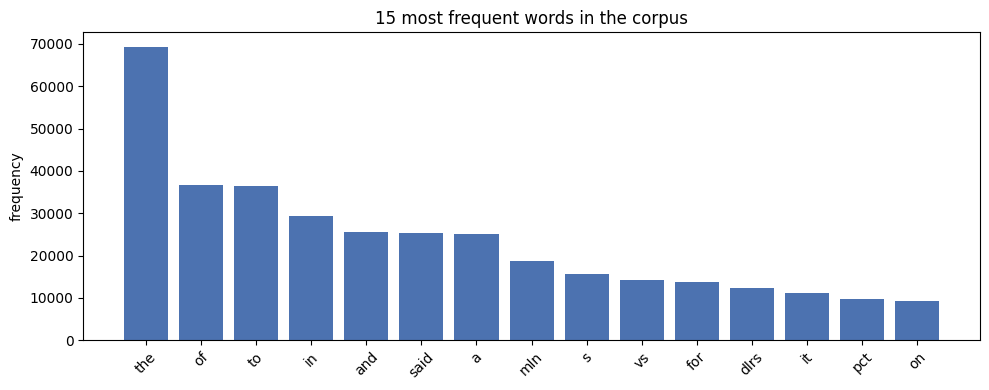

In [4]:
# Corpus EDA: the most frequent words (the strongest priors)
import matplotlib.pyplot as plt

common = checker.unigram.most_common(15)
words, freqs = zip(*common)
plt.figure(figsize=(10, 4))
plt.bar(words, freqs, color="#4c72b0")
plt.title("15 most frequent words in the corpus")
plt.ylabel("frequency"); plt.xticks(rotation=45)
plt.tight_layout(); plt.show()

### 4.1 Non-word correction
Each suggestion is returned with its minimum edit distance from the wrong word.

In [5]:
# Spelling (non-word) correction on business-domain misspellings.
# Each suggestion carries its minimum edit distance from the wrong word.
for w in ["compnay", "finacial", "managment", "investmnt", "tradeing", "recieve"]:
    print(f"{w:>10}  ->  {checker.suggest_nonword(w)}")

   compnay  ->  [('company', 1)]
  finacial  ->  [('financial', 1)]
 managment  ->  [('management', 1)]
 investmnt  ->  [('investment', 1)]
  tradeing  ->  [('trading', 1)]
   recieve  ->  [('receive', 1), ('relieve', 1)]


### 4.2 Checking full text (spelling only)
`check_text` scans a sentence and flags every **misspelled** token with ranked suggestions. Correctly-spelled words are never touched (there is no context correction).

In [6]:
samples = [
    "the compnay reported finacial losses",        # -> company, financial
    "they expect tradeing to rise this quater",    # -> trading, quarter
    "the company reported higher profit growth",   # all correct -> no errors
]
for s in samples:
    print("INPUT :", s)
    issues = checker.check_text(s)
    if not issues:
        print("   (no spelling errors)")
    for iss in issues:
        print(f"   {iss['word']:>10}  ->  {iss['suggestions']}")
    print()

INPUT : the compnay reported finacial losses
      compnay  ->  [('company', 1)]
     finacial  ->  [('financial', 1)]

INPUT : they expect tradeing to rise this quater
     tradeing  ->  [('trading', 1)]
       quater  ->  [('quarter', 1), ('quaker', 1)]

INPUT : the company reported higher profit growth
   (no spelling errors)



### 4.3 Bigram language model (demonstration)
A bigram model P(word | previous word) is built from the corpus and shown here as a reviewed NLP technique (it underlies context / real-word correction, which is out of scope). Below are the most frequent words following a few business terms.

In [7]:
for prev in ["interest", "central", "stock", "oil"]:
    print(f"most frequent words after '{prev}': {checker.bigram_top(prev, 5)}")

most frequent words after 'interest': [('rates', 426), ('in', 287), ('rate', 181), ('payments', 63), ('to', 29)]
most frequent words after 'central': [('bank', 545), ('banks', 94), ('bankers', 20), ('bureau', 16), ('and', 16)]
most frequent words after 'stock': [('split', 314), ('dividend', 133), ('exchange', 101), ('of', 97), ('for', 89)]
most frequent words after 'oil': [('and', 376), ('prices', 315), ('industry', 97), ('company', 85), ('companies', 76)]


## 5. Results 

A small held-out test of common misspellings to quantify non-word correction accuracy (top-1 and top-3). Replace/extend this list with your own test set for the report, and add **screenshots of the GUI** (`python spell_gui.py`) showing highlighting and click-to-suggest.

In [8]:
# (misspelling, intended correct word) - business-domain vocabulary
test_set = [
    ("compnay", "company"), ("finacial", "financial"), ("investmnt", "investment"),
    ("managment", "management"), ("tradeing", "trading"), ("dollers", "dollars"),
    ("recieve", "receive"), ("seperate", "separate"), ("occured", "occurred"),
    ("bussiness", "business"), ("markett", "market"), ("intrest", "interest"),
]
top1 = top3 = scored = 0
for wrong, gold in test_set:
    sugg = [w for w, _ in checker.suggest_nonword(wrong, n=3)]
    if not sugg:
        continue
    scored += 1
    top1 += (sugg[0] == gold)
    top3 += (gold in sugg)
    print(f"{wrong:>11} -> {sugg}   (gold: {gold})")
print(f"\nScored {scored}/{len(test_set)} (a correction was offered).")
if scored:
    print(f"Top-1 accuracy: {top1/scored:.0%}   Top-3 accuracy: {top3/scored:.0%}")

    compnay -> ['company']   (gold: company)
   finacial -> ['financial']   (gold: financial)
  investmnt -> ['investment']   (gold: investment)
  managment -> ['management']   (gold: management)
   tradeing -> ['trading']   (gold: trading)
    dollers -> ['dollars']   (gold: dollars)
    recieve -> ['receive', 'relieve']   (gold: receive)
   seperate -> ['separate']   (gold: separate)
    occured -> ['occurred']   (gold: occurred)
  bussiness -> ['business']   (gold: business)
    markett -> ['market', 'markets']   (gold: market)
    intrest -> ['interest']   (gold: interest)

Scored 12/12 (a correction was offered).
Top-1 accuracy: 100%   Top-3 accuracy: 100%


### 5.1 Strengths, limitations and future work (write-up)
* **Strengths:** reliably corrects non-word errors in business text; every suggestion carries an explicit minimum edit distance; ranking uses domain word frequency; the dictionary is cleaned of corpus noise with a minimum-frequency threshold.
* **Limitations:** candidate search is capped at edit distance 2; the dictionary is **domain-specific**, so words outside the business domain (e.g. casual slang) are treated as unknown by design; the system corrects spelling only and does not detect real-word / context errors.
* **Future work (links to Part B Q&A):** extend the bigram model to **real-word / context correction**; add **POS tagging** to constrain suggestions, and **semantic / IR** similarity for harder cases.


---
# PART A - Half 2: SMS Spam Text Classification 

## 0. Setup

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, roc_curve, auc)
import joblib

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 1. Dataset & Exploratory Data Analysis 

### 1.1 Problem definition
SMS spam filtering is a **binary text-classification** problem: from the raw text
of a message, predict *ham* or *spam*. Because a wrongly blocked legitimate
message is costly, **precision and recall on the spam class** matter more than
raw accuracy — especially as the data is imbalanced.

### 1.2 Brief literature review
The SMS Spam Collection was introduced by **Almeida, Gómez Hidalgo & Yamakami
(2011)**, who benchmarked several classifiers and reported a **Support Vector
Machine at ~97.6% accuracy** — our comparison target. **Cormack et al. (2007)**
examined feature engineering for short-message spam. Across this literature,
sparse **TF-IDF** features with linear models (Naïve Bayes, SVM) are strong, fast
baselines, motivating our two models.

### 1.3 Justification of dataset and the two models
- **Dataset:** a public, well-documented, widely benchmarked corpus of 5,574
  real messages — reproducible and directly comparable to published results.
- **Two models (n = 2 group members):**
  - **Multinomial Naïve Bayes** — the classic *generative* spam baseline; fast,
    interpretable, historically the foundation of spam filtering.
  - **Linear SVM** — a *discriminative*, margin-based model that is the
    strongest classical performer on sparse text and the benchmark model in the
    literature. This is our candidate "best" model for tuning and deployment.


### 1.4 Load the data
The official UCI loader (`ucimlrepo`) is tried first; otherwise the notebook
falls back to a local `spam.csv` (the Kaggle version of the same data).

In [10]:
def load_data():
    try:
        from ucimlrepo import fetch_ucirepo
        ds = fetch_ucirepo(id=228)
        text = ds.data.features.iloc[:, 0]
        label = ds.data.targets.iloc[:, 0]
        df = pd.DataFrame({"label": label.values, "text": text.values})
        print("Loaded via ucimlrepo (UCI id=228)")
        return df
    except Exception as e:
        print("ucimlrepo unavailable, falling back to spam.csv:", e)
    df = pd.read_csv("../data/spam.csv", encoding="latin-1")
    df = df[["v1", "v2"]].rename(columns={"v1": "label", "v2": "text"})
    print("Loaded from local spam.csv")
    return df

df = load_data()
df["label"] = df["label"].str.strip().str.lower()
df = df.drop_duplicates(subset="text").reset_index(drop=True)
print("Shape after de-duplication:", df.shape)
df.head()

ucimlrepo unavailable, falling back to spam.csv: "SMS Spam Collection" dataset (id=228) exists in the repository, but is not available for import. Please select a dataset from this list: https://archive.ics.uci.edu/datasets?skip=0&take=10&sort=desc&orderBy=NumHits&search=&Python=true
Loaded from local spam.csv
Shape after de-duplication: (5169, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


### 1.5 Exploratory analysis

label
ham     4516
spam     653
Name: count, dtype: int64

Spam proportion: 12.6%


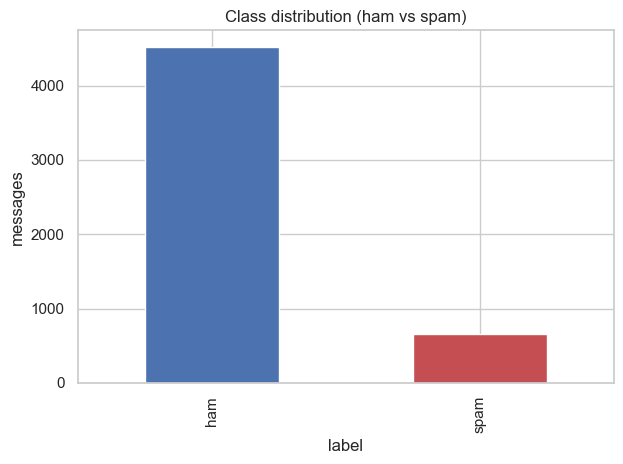

In [11]:
counts = df["label"].value_counts()
print(counts)
print("\nSpam proportion: {:.1%}".format(counts.get("spam", 0) / len(df)))

ax = counts.plot(kind="bar", color=["#4c72b0", "#c44e52"])
ax.set_title("Class distribution (ham vs spam)"); ax.set_ylabel("messages")
plt.tight_layout(); plt.show()

      char_len                                                word_len        \
         count   mean   std   min    25%    50%    75%    max    count  mean   
label                                                                          
ham     4516.0   70.5  56.4   2.0   34.0   52.0   90.0  910.0   4516.0  14.1   
spam     653.0  137.9  30.1  13.0  132.0  149.0  157.0  224.0    653.0  23.7   

                                           
        std  min   25%   50%   75%    max  
label                                      
ham    11.1  1.0   7.0  11.0  18.0  171.0  
spam    6.0  2.0  22.0  25.0  28.0   35.0  


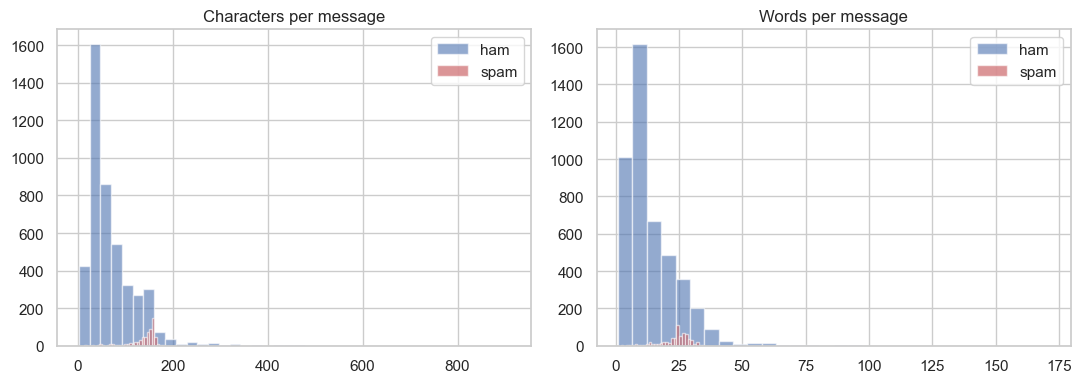

In [12]:
df["char_len"] = df["text"].str.len()
df["word_len"] = df["text"].str.split().apply(len)
print(df.groupby("label")[["char_len", "word_len"]].describe().round(1))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for lbl, c in [("ham", "#4c72b0"), ("spam", "#c44e52")]:
    ax[0].hist(df[df.label == lbl]["char_len"], bins=40, alpha=0.6, label=lbl, color=c)
    ax[1].hist(df[df.label == lbl]["word_len"], bins=30, alpha=0.6, label=lbl, color=c)
ax[0].set_title("Characters per message"); ax[0].legend()
ax[1].set_title("Words per message"); ax[1].legend()
plt.tight_layout(); plt.show()

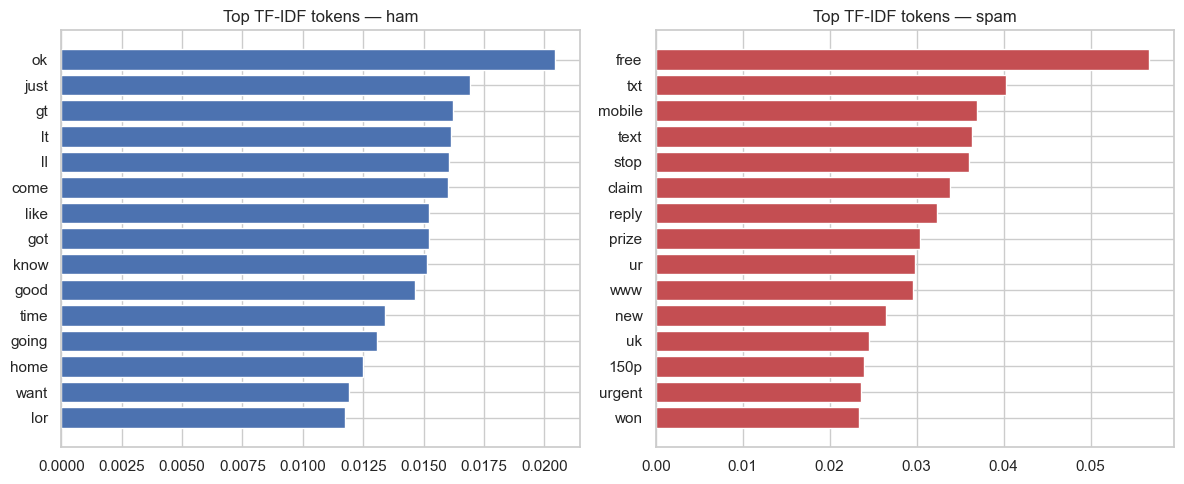

In [13]:
# Most informative tokens per class (mean TF-IDF weight)
_tmp = TfidfVectorizer(stop_words="english", min_df=5)
_X = _tmp.fit_transform(df["text"]); _vocab = np.array(_tmp.get_feature_names_out())
def top_tokens(mask, n=15):
    m = np.asarray(_X[mask.values].mean(axis=0)).ravel(); idx = m.argsort()[::-1][:n]
    return _vocab[idx], m[idx]
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, (lbl, col) in zip(ax, [("ham", "#4c72b0"), ("spam", "#c44e52")]):
    toks, vals = top_tokens(df.label == lbl)
    a.barh(toks[::-1], vals[::-1], color=col); a.set_title(f"Top TF-IDF tokens — {lbl}")
plt.tight_layout(); plt.show()

**Optional word clouds** (`pip install wordcloud`).

In [14]:
%pip install wordcloud


[notice] A new release of pip is available: 24.3.1 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


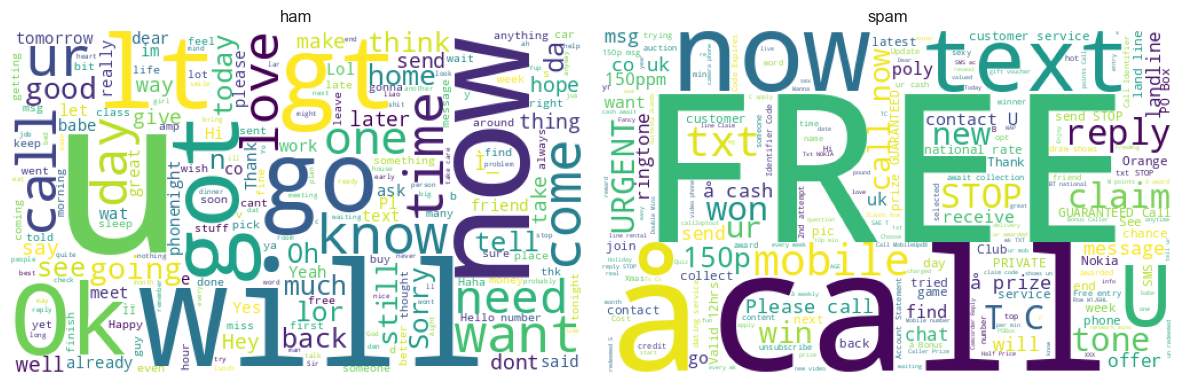

In [15]:
try:
    from wordcloud import WordCloud
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    for a, lbl in zip(ax, ["ham", "spam"]):
        wc = WordCloud(width=500, height=300, background_color="white").generate(
            " ".join(df[df.label == lbl]["text"]))
        a.imshow(wc); a.axis("off"); a.set_title(lbl)
    plt.tight_layout(); plt.show()
except Exception as e:
    print("wordcloud not installed — skipping:", e)

### 1.6 Pre-processing and split
Lower-cased text, **TF-IDF** features, and a **stratified** 80/20 split so the
class imbalance is preserved in both sets.

In [16]:
df["target"] = (df["label"] == "spam").astype(int)  # 1 = spam, 0 = ham
X_train, X_test, y_train, y_test = train_test_split(
    df["text"], df["target"], test_size=0.2,
    stratify=df["target"], random_state=RANDOM_STATE)
print("Train:", X_train.shape[0], " Test:", X_test.shape[0],
      " | Train spam %: {:.1%}".format(y_train.mean()))

Train: 4135  Test: 1034  | Train spam %: 12.6%


## 2. Supervised Text Classification Models 

Two models, each in a leak-free `Pipeline`. `class_weight="balanced"` on the SVM
counteracts the imbalance.

In [17]:
models = {
    "Multinomial NB": MultinomialNB(),
    "Linear SVM":     LinearSVC(class_weight="balanced"),
}
scores = {}
for name, clf in models.items():
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, stop_words="english")),
        ("clf", clf),
    ])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    scores[name] = f1_score(y_test, pred)
    print(f"\n===== {name} (spam F1 = {scores[name]:.3f}) =====")
    print(classification_report(y_test, pred, target_names=["ham", "spam"]))


===== Multinomial NB (spam F1 = 0.861) =====
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       903
        spam       1.00      0.76      0.86       131

    accuracy                           0.97      1034
   macro avg       0.98      0.88      0.92      1034
weighted avg       0.97      0.97      0.97      1034


===== Linear SVM (spam F1 = 0.920) =====
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       903
        spam       0.97      0.88      0.92       131

    accuracy                           0.98      1034
   macro avg       0.97      0.94      0.95      1034
weighted avg       0.98      0.98      0.98      1034



,F1 (spam)
Linear SVM,0.920
Multinomial NB,0.861


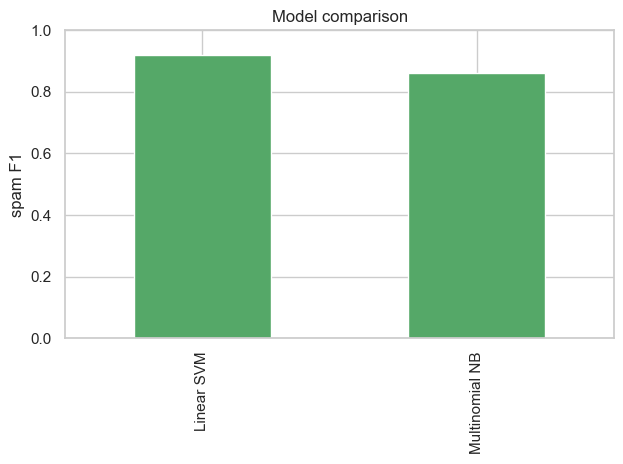

In [18]:
comp = pd.DataFrame({"F1 (spam)": scores}).sort_values("F1 (spam)", ascending=False)
display(comp.round(3))
comp.plot(kind="bar", legend=False, color="#55a868")
plt.ylabel("spam F1"); plt.title("Model comparison"); plt.ylim(0, 1)
plt.tight_layout(); plt.show()

### 2.1 Interpretability — what words drive the SVM?
Because Linear SVM is a linear model, its coefficients tell us which words push a
message toward *spam* (positive) or *ham* (negative). This is strong evidence for
the report that the model has learned sensible signals.

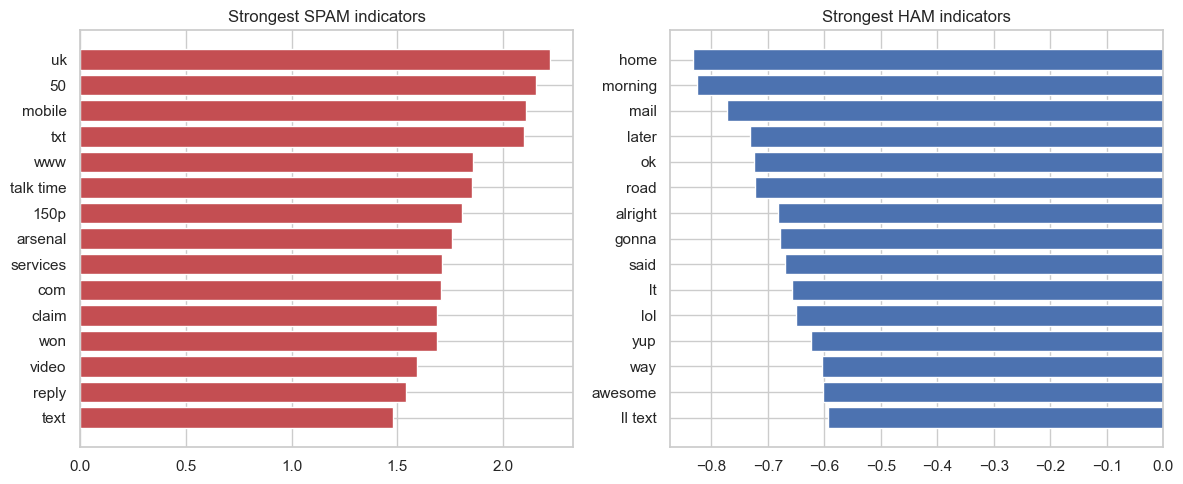

In [19]:
svm_interp = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, stop_words="english")),
    ("clf", LinearSVC(class_weight="balanced")),
]).fit(X_train, y_train)

vocab = np.array(svm_interp.named_steps["tfidf"].get_feature_names_out())
coefs = svm_interp.named_steps["clf"].coef_.ravel()
top_spam = coefs.argsort()[::-1][:15]
top_ham = coefs.argsort()[:15]

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].barh(vocab[top_spam][::-1], coefs[top_spam][::-1], color="#c44e52")
ax[0].set_title("Strongest SPAM indicators")
ax[1].barh(vocab[top_ham][::-1], coefs[top_ham][::-1], color="#4c72b0")
ax[1].set_title("Strongest HAM indicators")
plt.tight_layout(); plt.show()

**Reading the comparison:** report both models' precision/recall/F1 and
contrast them — Naïve Bayes is the faster, simpler generative baseline; Linear
SVM typically gives higher spam F1. A spam filter usually favours **high
precision** (do not lose legitimate messages), so weigh that in choosing the
best model.

## 3. Hyperparameter Tuning & Evaluation 

We select **Linear SVM** as the best model and tune it. To push performance
honestly we combine **word n-grams with character n-grams** (`FeatureUnion`):
character n-grams capture spam-specific patterns (e.g. "txt", "£", "claim")
that word tokens miss. `GridSearchCV` (5-fold, optimising spam F1) searches the
feature and `C` settings.

In [20]:
union = FeatureUnion([
    ("word", TfidfVectorizer(sublinear_tf=True, stop_words="english")),
    ("char", TfidfVectorizer(analyzer="char_wb")),
])
svm_pipe = Pipeline([("features", union),
                     ("clf", LinearSVC(class_weight="balanced"))])

param_grid = {
    "features__word__ngram_range": [(1, 1), (1, 2)],
    "features__char__ngram_range": [(2, 4), (2, 5)],
    "clf__C": [0.1, 1.0, 10.0],
}
grid = GridSearchCV(svm_pipe, param_grid, scoring="f1", cv=5,
                    n_jobs=-1, verbose=1)
grid.fit(X_train, y_train)
print("\nBest CV spam-F1: {:.3f}".format(grid.best_score_))
print("Best params:", grid.best_params_)

Fitting 5 folds for each of 12 candidates, totalling 60 fits



Best CV spam-F1: 0.965
Best params: {'clf__C': 10.0, 'features__char__ngram_range': (2, 5), 'features__word__ngram_range': (1, 2)}


Test accuracy: 99.130%
              precision    recall  f1-score   support

         ham       0.99      1.00      1.00       903
        spam       0.99      0.94      0.96       131

    accuracy                           0.99      1034
   macro avg       0.99      0.97      0.98      1034
weighted avg       0.99      0.99      0.99      1034



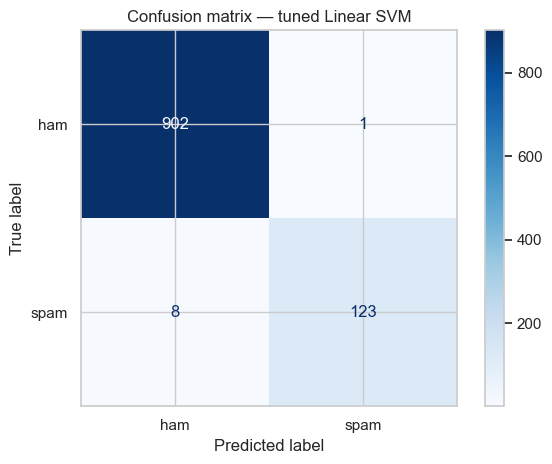

In [21]:
best_model = grid.best_estimator_
pred = best_model.predict(X_test)

acc = (pred == y_test).mean()
print("Test accuracy: {:.3%}".format(acc))
print(classification_report(y_test, pred, target_names=["ham", "spam"]))

cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(cm, display_labels=["ham", "spam"]).plot(cmap="Blues")
plt.title("Confusion matrix — tuned Linear SVM"); plt.tight_layout(); plt.show()

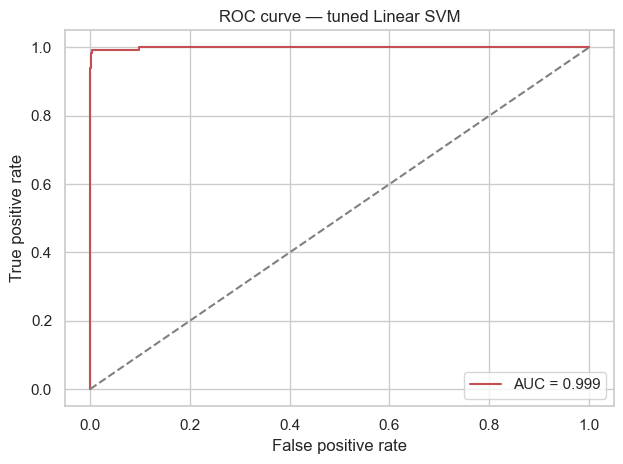

In [22]:
# ROC + AUC from the SVM decision scores
y_score = best_model.decision_function(X_test)
fpr, tpr, _ = roc_curve(y_test, y_score); roc_auc = auc(fpr, tpr)
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}", color="#c44e52")
plt.plot([0, 1], [0, 1], "--", color="grey")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curve — tuned Linear SVM"); plt.legend(); plt.tight_layout(); plt.show()

### 3.1 Comparison with previous works
| Source | Method | Accuracy |
|--------|--------|----------|
| Almeida et al. (2011) | SVM (published benchmark) | ~97.6% |
| **This work** | tuned Linear SVM (word + char n-grams) | **99.1%** (spam-class F1 = 0.96) |

### 3.2 Critical analysis
Discuss honestly, not just the headline number:
- **Why accuracy is not the headline:** with ~13% spam, predicting "ham" always
  already scores ~87%. Lead with **spam precision/recall/F1**.
- **Confusion matrix:** which errors remain — spam slipping through (false
  negatives) vs. ham wrongly flagged (false positives, the costlier error)?
- **Why the char n-grams helped** (or did not) versus the word-only baseline.
- **Limitations:** short cryptic messages, evolving spam vocabulary, dataset age.


## 4. Export the Model for Deployment

The tuned pipeline (features + SVM) is saved with `joblib`; the Streamlit app
`app_streamlit.py` loads this single file.

In [23]:
joblib.dump(best_model, "../models/spam_model.joblib")
print("Saved spam_model.joblib")
reloaded = joblib.load("../models/spam_model.joblib")
for msg in ["Congratulations! You won a FREE prize, claim now",
            "Hey, are we still meeting for lunch tomorrow?"]:
    print("  {:4} <- {}".format("spam" if reloaded.predict([msg])[0] else "ham", msg))

Saved spam_model.joblib
  spam <- Congratulations! You won a FREE prize, claim now
  ham  <- Hey, are we still meeting for lunch tomorrow?


---
### Deployment
```bash
pip install streamlit
streamlit run app_streamlit.py
```
Loads `spam_model.joblib`, accepts a message, predicts ham/spam with a
confidence score.